<a href="https://colab.research.google.com/github/rodrigoiyg27/TopicosEspeciales2026/blob/main/Clase8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

URL = ("https://media.githubusercontent.com/media/StackExchange/Survey/"
       "main/packages/archive/2025/results.csv")


columnas = ["MainBranch", "Employment", "Country", "WorkExp", "RemoteWork",
            "LanguageHaveWorkedWith", "ConvertedCompYearly"]
so = pd.read_csv(URL, usecols=columnas, low_memory=False)
print(so.shape)


(49191, 7)


In [ ]:
# Regla del curso para analizar salarios:
# 1) desarrolladores profesionales, 2) empleados o freelancers,
# 3) salario anual entre 1 mil y 1 millón de USD
empleo = ["Employed", "Independent contractor, freelancer, or self-employed"]
profesionales = so[(so["MainBranch"] == "I am a developer by profession")
                   & so["Employment"].isin(empleo)]
salarios = profesionales[profesionales["ConvertedCompYearly"].between(1_000, 1_000_000)]
print(len(profesionales), len(salarios))

34146 19025


Creación del gráfico

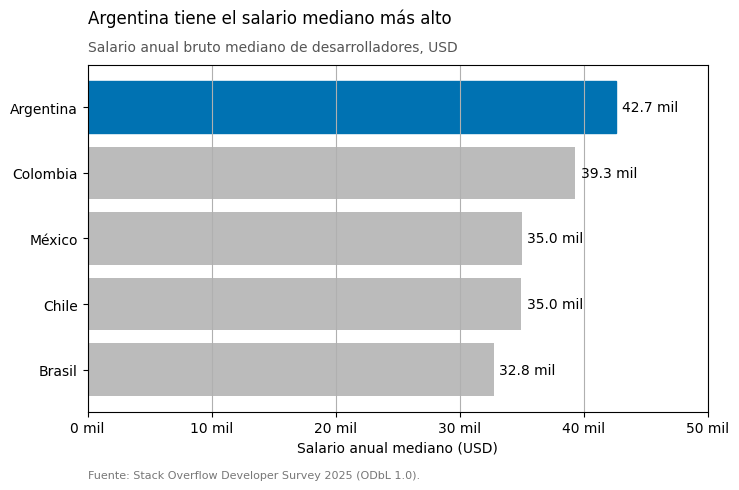

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Mediana salarial de cinco países con muchas respuestas, ordenada (elemento 10)
paises = {"Brazil": "Brasil", "Mexico": "México", "Argentina": "Argentina",
          "Colombia": "Colombia", "Chile": "Chile"}
mediana = (salarios[salarios["Country"].isin(paises)]
           .groupby("Country")["ConvertedCompYearly"].median()
           .rename(index=paises).sort_values())

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.barh(mediana.index, mediana.values, color="#BBBBBB")
barras[-1].set_color("#0072B2")                                    # 3: un solo acento
ax.bar_label(barras, labels=[f"{v/1000:.1f} mil" for v in mediana], padding=4)   # 4
ax.grid(axis="x"); ax.grid(axis="y", visible=False)               # 5: grilla vertical
ax.set_xlim(0, 50_000)                                             # 6: desde cero
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1000:.0f} mil"))  # 7
ax.set_xlabel("Salario anual mediano (USD)")                       # 8

ax.set_title("Argentina tiene el salario mediano más alto", loc="left", pad=30)   # 1
ax.annotate("Salario anual bruto mediano de desarrolladores, USD",  # 2: subtítulo
            xy=(0, 1), xycoords="axes fraction", xytext=(0, 8),
            textcoords="offset points", color="#555555", va="bottom")
ax.annotate("Fuente: Stack Overflow Developer Survey 2025 (ODbL 1.0).",   # 9
            xy=(0, 0), xycoords="axes fraction", xytext=(0, -42),
            textcoords="offset points", fontsize=8, color="#777777", va="top")
plt.show()

Regla de estilo

In [ ]:
%%writefile curso.mplstyle
# --- Dimensiones y resolución
figure.figsize     : 8, 4.5     # 16:9, sirve para slide e informe
figure.dpi         : 110
savefig.dpi        : 200
savefig.bbox       : tight      # no recorta título ni fuente
# --- Tipografía: una sola familia, disponible en cualquier equipo
font.family        : sans-serif
font.sans-serif    : DejaVu Sans, Arial, Helvetica
font.size          : 10
# --- Título alineado a la izquierda, en negrita
axes.titlelocation : left
axes.titlesize     : 13
axes.titleweight   : bold
# --- Ejes: solo la línea base, sin marco
axes.spines.top    : False
axes.spines.right  : False
axes.spines.left   : False
ytick.major.size   : 0
# --- Grilla clara y detrás de los datos
axes.grid          : True
axes.grid.axis     : y
grid.color         : DDDDDD
axes.axisbelow     : True
# --- Leyenda sin marco
legend.frameon     : False
# --- Series: paleta Okabe-Ito, apta para daltonismo, en orden fijo
axes.prop_cycle    : cycler('color', ['0072B2', 'E69F00', '009E73', 'D55E00', '56B4E9', 'CC79A7'])
patch.edgecolor    : white

Writing curso.mplstyle


Gráfico anterior con la nueva regla

In [ ]:
import matplotlib.pyplot as plt
plt.style.use("curso.mplstyle")

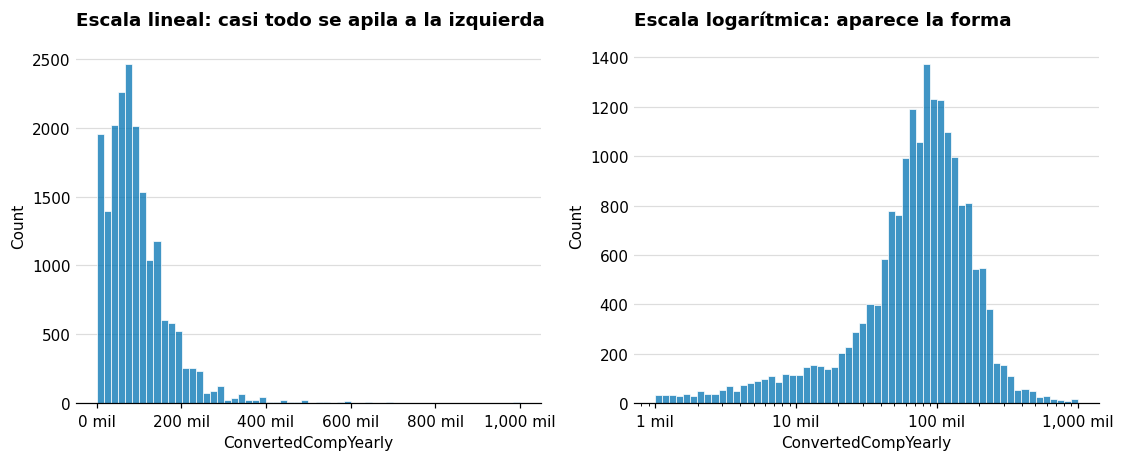

In [ ]:
import seaborn as sns
import matplotlib.ticker as mticker
def encabezado(ax, titulo, subtitulo=None):
    ax.set_title(titulo, loc="left", pad=30 if subtitulo else 15, fontsize=12, fontweight="bold")
    if subtitulo:
        ax.annotate(subtitulo,
                    xy=(0, 1), xycoords="axes fraction", xytext=(0, 8),
                    textcoords="offset points", color="#555555", va="bottom", fontsize=9)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

# Escala lineal: la cola de salarios altos aplasta el resto
sns.histplot(data=salarios, x="ConvertedCompYearly", bins=60, ax=ax1)
encabezado(ax1, "Escala lineal: casi todo se apila a la izquierda")

# Escala log: log_scale=True calcula los bins sobre log10(salario)
sns.histplot(data=salarios, x="ConvertedCompYearly", bins=60, log_scale=True, ax=ax2)
encabezado(ax2, "Escala logarítmica: aparece la forma")

for ax in (ax1, ax2):
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1000:,.0f} mil"))
plt.show()

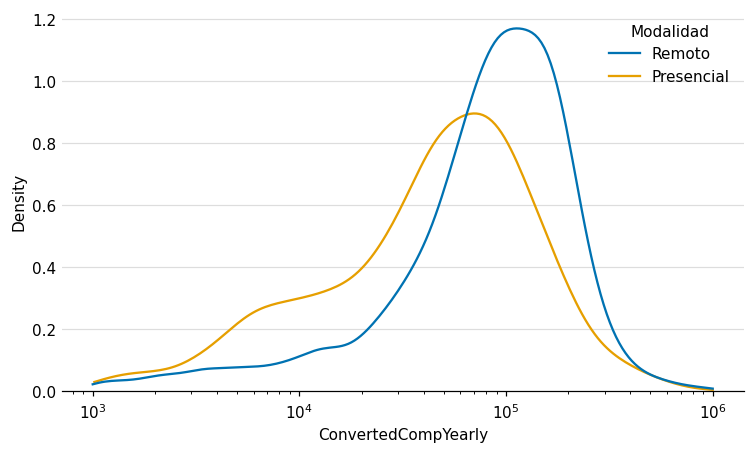

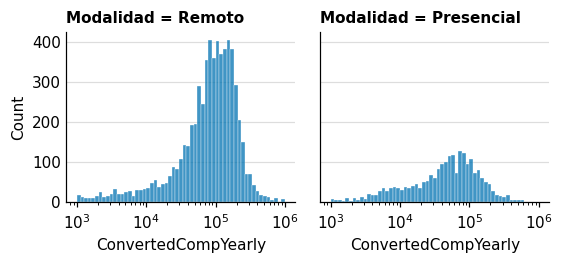

In [ ]:
# Mapeamos los valores de RemoteWork a etiquetas más cortas en la nueva columna 'Modalidad'
mapa_modalidad = {
    "Remote": "Remoto",
    "Hybrid": "Híbrido",
    "In-person": "Presencial"
}
salarios = salarios.copy()
salarios["Modalidad"] = salarios["RemoteWork"].map(mapa_modalidad)

# Filtramos las filas que no tienen modalidad definida para evitar nulos en el gráfico
salarios_filtrados = salarios.dropna(subset=["Modalidad"])

# Curvas de densidad: varias distribuciones se distinguen mejor que histogramas superpuestos
# cut=0 evita que la curva invente valores fuera del rango observado (Wilke, p. 63-64)
sns.kdeplot(data=salarios_filtrados, x="ConvertedCompYearly", hue="Modalidad",
            log_scale=True, cut=0, common_norm=False)
plt.show()

# Alternativa: un panel por grupo, todos con el mismo eje X
sns.displot(data=salarios_filtrados, x="ConvertedCompYearly", col="Modalidad", col_wrap=3,
            log_scale=True, height=2.5)
plt.show()

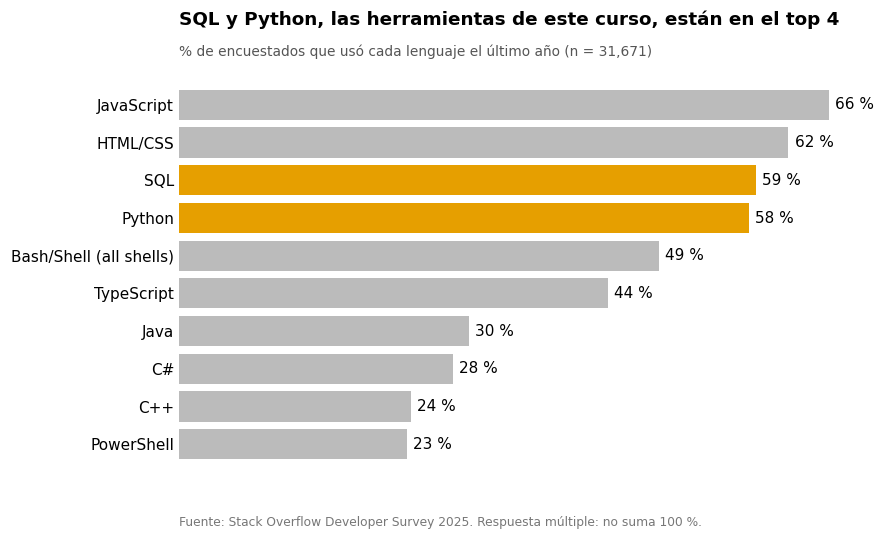

In [ ]:
# Definimos las funciones auxiliares para el estilo
def encabezado(ax, titulo, subtitulo=None):
    ax.set_title(titulo, loc="left", pad=30 if subtitulo else 15, fontsize=12, fontweight="bold")
    if subtitulo:
        ax.annotate(subtitulo,
                    xy=(0, 1), xycoords="axes fraction", xytext=(0, 8),
                    textcoords="offset points", color="#555555", va="bottom", fontsize=9)

def pie_de_figura(ax, texto):
    ax.annotate(texto,
                xy=(0, 0), xycoords="axes fraction", xytext=(0, -25),
                textcoords="offset points", fontsize=8, color="#777777", va="top")

# 1) Cuántas personas respondieron la pregunta (base de los porcentajes)
n_resp = so["LanguageHaveWorkedWith"].notna().sum()

# 2) "Python;SQL;Bash" -> una fila por lenguaje, luego contar
lenguajes = (so["LanguageHaveWorkedWith"].dropna()
             .str.split(";").explode()
             .value_counts().head(10) / n_resp * 100)
lenguajes = lenguajes.sort_values()      # orden ascendente: barh dibuja de abajo hacia arriba

# 3) Gris para todos, acento para lo que queremos mostrar
colores = ["#E69F00" if l in ("SQL", "Python") else "#BBBBBB" for l in lenguajes.index]

fig, ax = plt.subplots(figsize=(8, 4.8))
barras = ax.barh(lenguajes.index, lenguajes.values, color=colores)
ax.bar_label(barras, fmt="%.0f %%", padding=4)    # el valor exacto en cada barra...
ax.grid(False)                                       # ...hace innecesaria la grilla
ax.tick_params(axis="x", labelbottom=False, length=0)
ax.spines["bottom"].set_visible(False)

encabezado(ax, "SQL y Python, las herramientas de este curso, están en el top 4",
           f"% de encuestados que usó cada lenguaje el último año (n = {n_resp:,})")
pie_de_figura(ax, "Fuente: Stack Overflow Developer Survey 2025. Respuesta múltiple: no suma 100 %.")
plt.show()

Dispersión

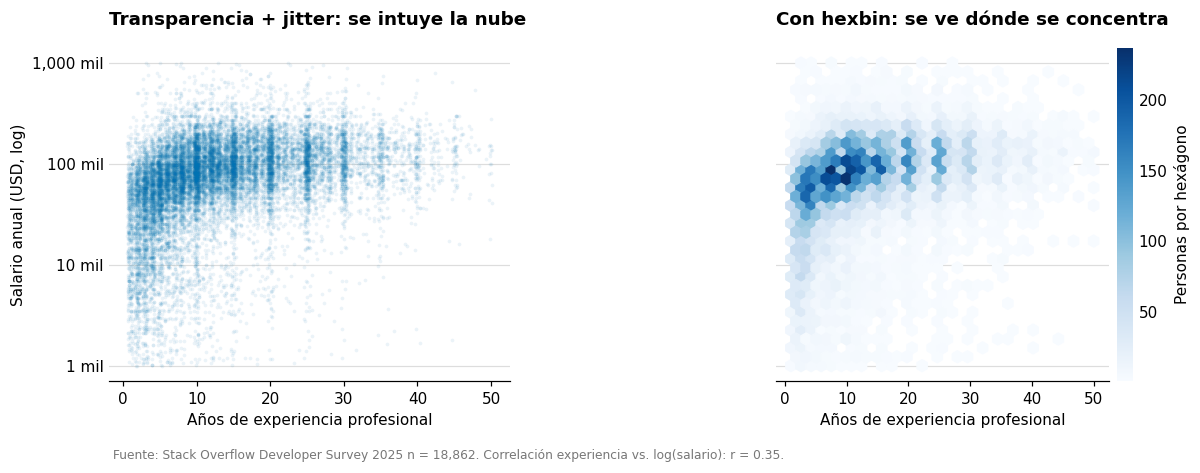

In [ ]:
import numpy as np
import matplotlib.ticker as mticker

xy = salarios.dropna(subset=["WorkExp"])
xy = xy[xy["WorkExp"] <= 50]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)

# Izquierda: jitter (los años son enteros) + mucha transparencia
rng = np.random.default_rng(42)                     # semilla: el gráfico es reproducible
x_jitter = xy["WorkExp"] + rng.uniform(-0.4, 0.4, len(xy))
# Corregido: usando "#0072B2" como color azul
ax1.scatter(x_jitter, xy["ConvertedCompYearly"], s=6, color="#0072B2", alpha=0.08, linewidths=0)
ax1.set_yscale("log")
ax1.set(xlabel="Años de experiencia profesional",    # título del eje X, con unidad
        ylabel="Salario anual (USD, log)")         # el eje Y lo comparten ambos paneles
encabezado(ax1, "Transparencia + jitter: se intuye la nube")

# Derecha: hexbin, el color secuencial indica cuántas personas hay en cada celda
hb = ax2.hexbin(xy["WorkExp"], xy["ConvertedCompYearly"], gridsize=30,
                yscale="log", cmap="Blues", mincnt=1)
cb = fig.colorbar(hb, ax=ax2, pad=0.02, label="Personas por hexágono")
cb.outline.set_visible(False)
ax2.set(xlabel="Años de experiencia profesional")    # cada panel lleva su título de eje X
encabezado(ax2, "Con hexbin: se ve dónde se concentra")

# Definimos el formateador para los miles
miles = mticker.FuncFormatter(lambda v, _: f"{v/1000:,.0f} mil")

# Formato del eje Y después del hexbin (hexbin lo reinicia): 100000 -> "100 mil"
for ax in (ax1, ax2):
    ax.yaxis.set_major_formatter(miles)
    ax.yaxis.set_minor_locator(mticker.NullLocator())

# Correlación sobre log(salario), coherente con la escala del gráfico
r = np.corrcoef(xy["WorkExp"], np.log10(xy["ConvertedCompYearly"]))[0, 1]

# Fuente y nota abajo a la izquierda, con n y r para que el lector juzgue el dato
pie_de_figura(ax1, "\n\n Fuente: Stack Overflow Developer Survey 2025" + f" n = {len(xy):,}. Correlación experiencia vs. log(salario): r = {r:.2f}.")
fig.tight_layout()
plt.show()

Boxplots

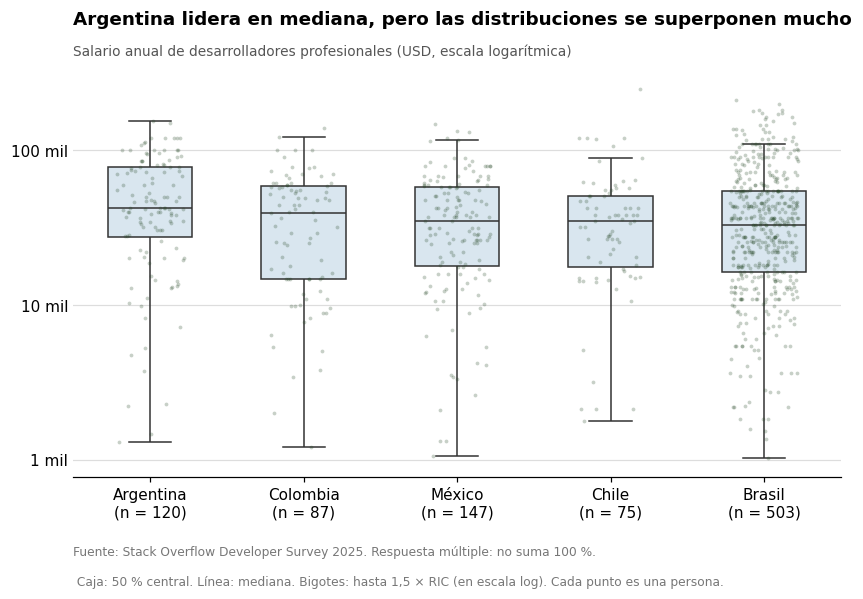

In [ ]:
paises = {"Brazil": "Brasil", "Mexico": "México", "Argentina": "Argentina",
          "Colombia": "Colombia", "Chile": "Chile"}
bx = salarios[salarios["Country"].isin(paises)].copy()
bx["País"] = bx["Country"].map(paises)

# Ordenar por mediana, de mayor a menor (Schwabish, p. 198)
orden = bx.groupby("País")["ConvertedCompYearly"].median().sort_values(ascending=False).index
conteo = bx["País"].value_counts()

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.boxplot(data=bx, x="País", y="ConvertedCompYearly", order=orden, color="#D6E6F2",
            width=0.55, showfliers=False, linecolor="#333333", ax=ax)  # sin outliers: ya van los puntos
sns.stripplot(data=bx, x="País", y="ConvertedCompYearly", order=orden, color="#242",
              alpha=0.25, size=2.5, jitter=0.22, ax=ax)                 # cada punto es una persona
ax.set_yscale("log")
ax.yaxis.set_major_formatter(miles)
ax.yaxis.set_minor_locator(mticker.NullLocator())

# Mostrar el tamaño de cada grupo en la etiqueta: n distintos = distinta confianza
ax.set_xticks(range(len(orden)), [f"{p}\n(n = {conteo[p]})" for p in orden])
ax.set(xlabel="", ylabel="")    # los países se explican solos; la unidad va en el subtítulo

encabezado(ax, "Argentina lidera en mediana, pero las distribuciones se superponen mucho",
           "Salario anual de desarrolladores profesionales (USD, escala logarítmica)")
# La nota explica cómo leer la caja: el lector no tiene por qué conocer la convención
pie_de_figura(ax, "\n\nFuente: Stack Overflow Developer Survey 2025. Respuesta múltiple: no suma 100 %." + "\n\n Caja: 50 % central. Línea: mediana. Bigotes: hasta 1,5 × RIC "
              "(en escala log). Cada punto es una persona.")
plt.show()